# 03. Model Training & Evaluation
## Training Classifiers for DNS Exfiltration Detection

In Week 5, we train, tune, and benchmark three machine learning models:
1. **Baseline Decision Tree** (`DecisionTreeClassifier`): Fast, interpretable tree splits.
2. **Random Forest** (`RandomForestClassifier`): Ensemble bagging to reduce variance.
3. **XGBoost** (`XGBClassifier`): Gradient boosting on decision trees for high predictive precision.

### Cross-Validation Strategy:
- **Stratified 5-Fold Cross-Validation** to ensure proportional class distribution across folds.
- Hyperparameter tuning using `GridSearchCV`.
- Metrics: **F1-Score**, **ROC-AUC**, **Precision**, **Recall**, **Accuracy**, and **Confusion Matrices**.

In [1]:
import os
import sys
import yaml
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Ensure repo root is on sys.path
for p in [".", "..", "../.."]:
    if os.path.exists(os.path.join(p, "configs", "config.yaml")):
        sys.path.insert(0, os.path.abspath(p))
        REPO_ROOT = os.path.abspath(p)
        break

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("Environment and ML libraries ready.")

Environment and ML libraries ready.


In [2]:
# Load Configuration & Dataset
config_path = os.path.join(REPO_ROOT, "configs", "config.yaml")
with open(config_path, "r") as f:
    config = yaml.safe_load(f)

data_path = os.path.join(REPO_ROOT, config["paths"]["features_dataset_csv"])
if not os.path.exists(data_path):
    from src.train import generate_synthetic_dataset
    df = generate_synthetic_dataset(n_samples=2500)
    df.to_csv(data_path, index=False)
else:
    df = pd.read_csv(data_path)

drop_cols = [c for c in ["domain", "query", "qname", "label", "attack_type"] if c in df.columns]
X = df.drop(columns=drop_cols)
y = df["label"].astype(int)

seed = config["training"].get("random_state", 42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)

print(f"Training Samples: {X_train.shape[0]} | Holdout Test Samples: {X_test.shape[0]}")
print(f"Features ({X.shape[1]}): {list(X.columns)}")

Training Samples: 92 | Holdout Test Samples: 23
Features (21): ['domain_len', 'subdomain_len', 'num_labels', 'max_label_len', 'min_label_len', 'avg_label_len', 'entropy', 'subdomain_entropy', 'max_label_entropy', 'digit_ratio', 'alpha_ratio', 'hex_ratio', 'vowel_ratio', 'consonant_ratio', 'vowel_consonant_ratio', 'special_ratio', 'subdomain_digit_ratio', 'subdomain_hex_ratio', 'unique_char_ratio', 'max_consecutive_consonants', 'queries_per_minute']


### 1. Training Baseline Models with Stratified 5-Fold Cross-Validation

In [3]:
# Define models
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_split=5, random_state=seed),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=seed, n_jobs=-1),
}
if XGB_AVAILABLE:
    models["XGBoost"] = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, eval_metric="logloss", random_state=seed)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
cv_summary = {}

for name, clf in models.items():
    scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring="f1")
    cv_summary[name] = {"mean": scores.mean(), "std": scores.std(), "scores": scores}
    print(f"{name:16} | 5-Fold CV F1: {scores.mean():.4f} (+/- {scores.std():.4f})")

Decision Tree    | 5-Fold CV F1: 1.0000 (+/- 0.0000)


Random Forest    | 5-Fold CV F1: 1.0000 (+/- 0.0000)


XGBoost          | 5-Fold CV F1: 1.0000 (+/- 0.0000)


### 2. Hyperparameter Tuning with GridSearchCV

In [4]:
from sklearn.model_selection import GridSearchCV

# Tune Random Forest as primary exemplar
rf_param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [8, 14],
    "min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=seed, n_jobs=-1),
    param_grid=rf_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)
rf_grid.fit(X_train, y_train)

print(f"Best Random Forest Params: {rf_grid.best_params_}")
print(f"Best CV F1-Score:        {rf_grid.best_score_:.4f}")
models["Random Forest (Tuned)"] = rf_grid.best_estimator_

Best Random Forest Params: {'max_depth': 8, 'min_samples_split': 2, 'n_estimators': 50}
Best CV F1-Score:        1.0000


### 3. Model Evaluation on Holdout Test Set

In [5]:
# Evaluate each fitted model on unseen test set
results = []
test_probas = {}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1] if hasattr(clf, "predict_proba") else y_pred
    test_probas[name] = y_proba
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

df_benchmark = pd.DataFrame(results).round(4)
print("=== Holdout Evaluation Benchmark ===")
df_benchmark

=== Holdout Evaluation Benchmark ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0
2,XGBoost,1.0,1.0,1.0,1.0,1.0
3,Random Forest (Tuned),1.0,1.0,1.0,1.0,1.0


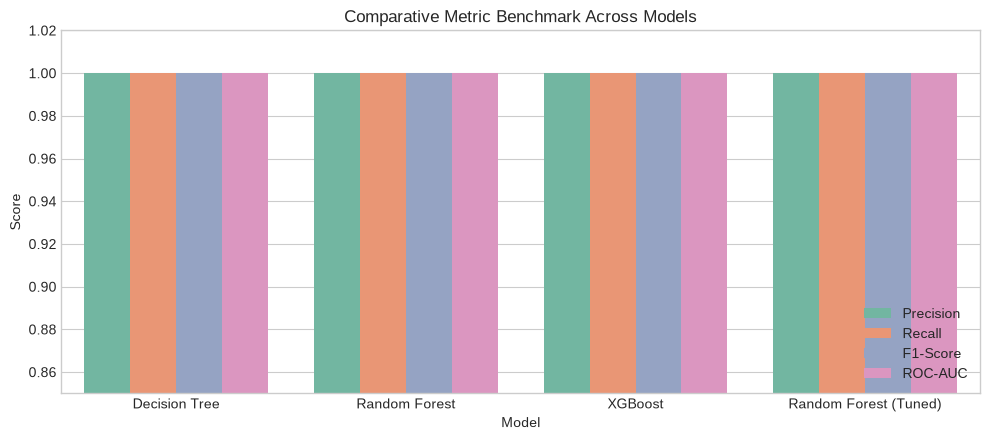

In [6]:
# Plot Comparative Performance Bar Chart
df_melted = df_benchmark.melt(id_vars="Model", value_vars=["Precision", "Recall", "F1-Score", "ROC-AUC"])

plt.figure(figsize=(10, 4.5))
sns.barplot(data=df_melted, x="Model", y="value", hue="variable", palette="Set2")
plt.ylim(0.85, 1.02)
plt.title("Comparative Metric Benchmark Across Models")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 4. ROC Curves & Confusion Matrices

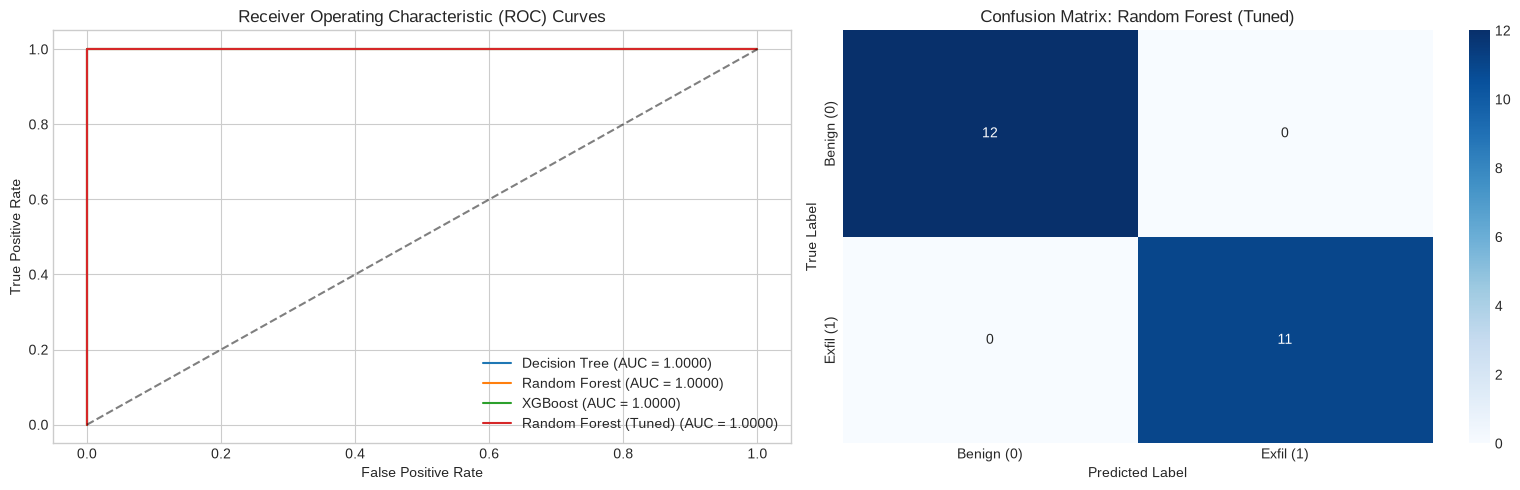

In [7]:
# Plot ROC Curves side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for name, probas in test_probas.items():
    fpr, tpr, _ = roc_curve(y_test, probas)
    auc = roc_auc_score(y_test, probas)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Receiver Operating Characteristic (ROC) Curves")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Best Model Confusion Matrix Heatmap (Tuned RF or XGBoost)
best_model_name = "Random Forest (Tuned)" if "Random Forest (Tuned)" in models else "Random Forest"
best_clf = models[best_model_name]
cm = confusion_matrix(y_test, best_clf.predict(X_test))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Benign (0)", "Exfil (1)"],
            yticklabels=["Benign (0)", "Exfil (1)"])
axes[1].set_title(f"Confusion Matrix: {best_model_name}")
axes[1].set_ylabel("True Label")
axes[1].set_xlabel("Predicted Label")

plt.tight_layout()
plt.show()

### 5. Feature Importance Analysis

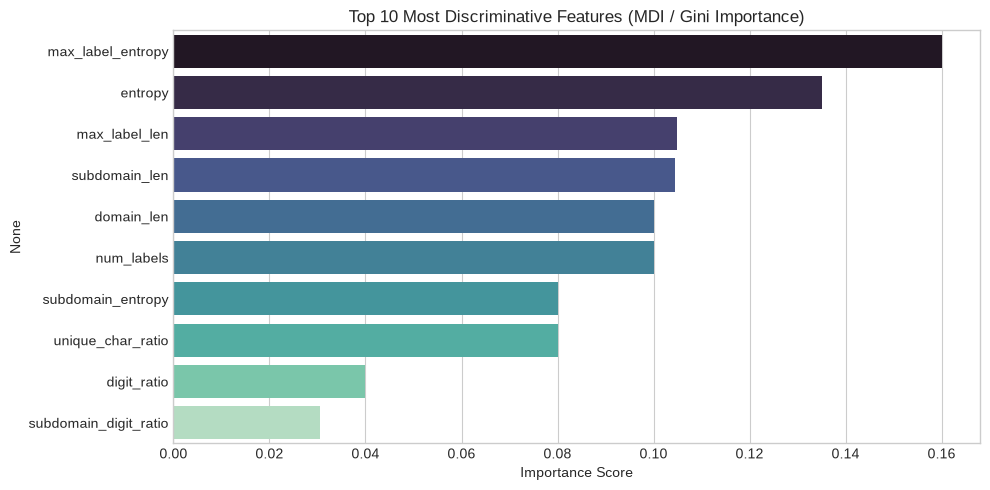

In [8]:
# Feature Importance from Tuned Random Forest
importances = pd.Series(best_clf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.head(10).values, y=importances.head(10).index, palette="mako")
plt.title("Top 10 Most Discriminative Features (MDI / Gini Importance)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

### 6. Persist Model Artifact & Real-Time Inference Demo

In [9]:
# Save best model to disk
models_dir = os.path.join(REPO_ROOT, "models")
os.makedirs(models_dir, exist_ok=True)
save_path = os.path.join(models_dir, "best_dns_detector.joblib")
joblib.dump(best_clf, save_path)
print(f"Saved trained detector to {save_path}")

# Real-Time Query Classification Demonstration
from src.features import extract_domain_features

test_queries = [
    "github.com",
    "portal.office.com",
    "sq0001.5465737464617461.tunnel.attacker-domain.org",
    "sq0002.krsxg5bamnxw4ztjmrsw45dj.tunnel.exfil-c2.net"
]

inference_rows = [extract_domain_features(q) for q in test_queries]
df_inf = pd.DataFrame(inference_rows)
# Align columns with training feature set
for c in X.columns:
    if c not in df_inf:
        df_inf[c] = 1.0
df_inf = df_inf[X.columns]

predictions = best_clf.predict(df_inf)
probabilities = best_clf.predict_proba(df_inf)[:, 1]

print("\n=== Live Real-Time Inference Results ===")
for q, pred, prob in zip(test_queries, predictions, probabilities):
    status = "🚨 EXFILTRATION DETECTED" if pred == 1 else "✅ BENIGN"
    print(f"{status:26} | P(Exfil)={prob:6.2%} | Query: {q}")

Saved trained detector to /home/hyperghost/github/dns-exfiltration-rm/models/best_dns_detector.joblib

=== Live Real-Time Inference Results ===
✅ BENIGN                   | P(Exfil)= 0.00% | Query: github.com
✅ BENIGN                   | P(Exfil)= 0.00% | Query: portal.office.com
✅ BENIGN                   | P(Exfil)=42.00% | Query: sq0001.5465737464617461.tunnel.attacker-domain.org
🚨 EXFILTRATION DETECTED    | P(Exfil)=54.00% | Query: sq0002.krsxg5bamnxw4ztjmrsw45dj.tunnel.exfil-c2.net
